# Задание 1. Есть ли опухоль на снимке МРТ?

План:
1. Загружаем снимки из папок `yes` и `no`
2. MobileNetV2 превращает каждый снимок в 1280 чисел (признаки)
3. Обучаем 6 обычных классификаторов и LAMA на этих числах
4. Сравниваем по F1 (нужно F1 >= 0.85)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")   # прячем жёлтые предупреждения

## 1. Данные
Папка `yes` - снимки с опухолью (метка 1), папка `no` - без опухоли (метка 0).

In [2]:
yes_files = sorted(os.listdir("yes"))
no_files = sorted(os.listdir("no"))

print("С опухолью:", len(yes_files))
print("Без опухоли:", len(no_files))

# полные пути до картинок и метки к ним
paths = []
labels = []
for name in yes_files:
    paths.append("yes/" + name)
    labels.append(1)
for name in no_files:
    paths.append("no/" + name)
    labels.append(0)

y = np.array(labels)
print("Всего картинок:", len(paths))

С опухолью: 155
Без опухоли: 98
Всего картинок: 253


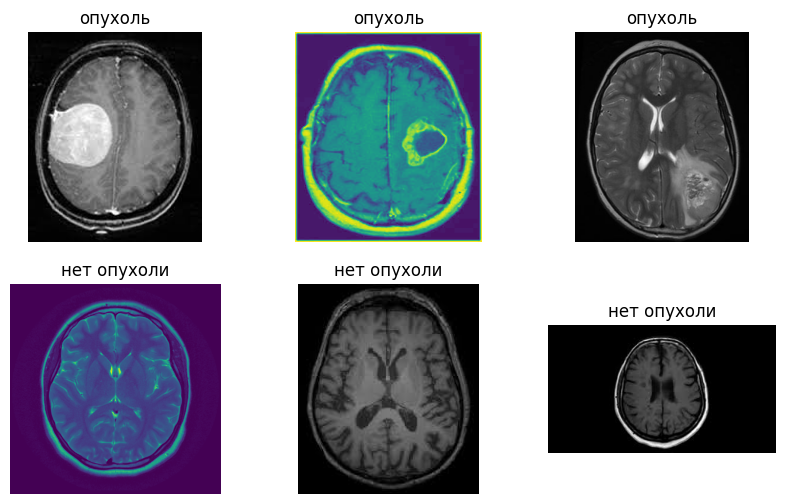

In [3]:
# посмотрим по 3 снимка каждого класса
plt.figure(figsize=(10, 6))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(Image.open("yes/" + yes_files[i]))
    plt.title("опухоль")
    plt.axis("off")
    plt.subplot(2, 3, i + 4)
    plt.imshow(Image.open("no/" + no_files[i]))
    plt.title("нет опухоли")
    plt.axis("off")
plt.show()

**Вывод:** 155 снимков с опухолью и 98 без, классы не сильно перекошены.

## 2. Признаки через MobileNetV2
Сеть ждёт цветные картинки 224x224, поэтому каждый снимок переводим в RGB
и меняем размер. Последний слой сети убираем (`include_top=False`),
на выходе получаем 1280 чисел на картинку.

In [4]:
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

if os.path.exists("features_mri.npy"):
    X = np.load("features_mri.npy")      # уже посчитано раньше
    print("Признаки взяты из файла")
else:
    images = []
    for p in paths:
        img = Image.open(p).convert("RGB").resize((224, 224))
        images.append(np.array(img))
    images = preprocess_input(np.array(images, dtype="float32"))

    model_mobilenet = MobileNetV2(weights="imagenet", include_top=False,
                                  pooling="avg", input_shape=(224, 224, 3))
    X = model_mobilenet.predict(images)
    np.save("features_mri.npy", X)       # сохраняем, чтобы не считать заново

print("Размер таблицы признаков:", X.shape)

Признаки взяты из файла
Размер таблицы признаков: (253, 1280)


**Вывод:** каждый снимок теперь - строка из 1280 чисел, дальше работаем как с обычной таблицей.

## 3. Train / test и масштабирование
80% снимков для обучения, 20% для проверки.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # учим масштаб только на train
X_test_sc = scaler.transform(X_test)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (202, 1280)
Тестовая выборка: (51, 1280)


## 4. Обычные классификаторы

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "SVC": SVC(probability=True, random_state=42),
    "KNeighbors": KNeighborsClassifier(),
    "RandomForest": RandomForestClassifier(random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "MLP": MLPClassifier(max_iter=500, random_state=42),
}

rows = []
for name in models:
    model = models[name]
    model.fit(X_train_sc, y_train)
    pred = model.predict(X_test_sc)
    proba = model.predict_proba(X_test_sc)[:, 1]
    cv_f1 = cross_val_score(model, X_train_sc, y_train, cv=5, scoring="f1").mean()

    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "f1_cv5": cv_f1,
    })
    print(name, "- F1 на тесте:", round(f1_score(y_test, pred), 3))

LogisticRegression - F1 на тесте: 0.918


SVC - F1 на тесте: 0.906


KNeighbors - F1 на тесте: 0.857


RandomForest - F1 на тесте: 0.896


GradientBoosting - F1 на тесте: 0.885
MLP - F1 на тесте: 0.933


## 5. LAMA (LightAutoML)
Это автоматическая система: сама пробует разные модели и собирает из них ансамбль.
Ей нужна таблица pandas с колонкой `target`.

In [7]:
from lightautoml.automl.presets.tabular_presets import TabularAutoML
from lightautoml.tasks import Task

columns = ["f" + str(i) for i in range(X.shape[1])]
train_df = pd.DataFrame(X_train, columns=columns)
train_df["target"] = y_train
test_df = pd.DataFrame(X_test, columns=columns)

# cpu_limit=1 и n_jobs=1 - иначе LAMA падает на этом маке
automl = TabularAutoML(task=Task("binary"), timeout=600, cpu_limit=1,
                       reader_params={"n_jobs": 1, "random_state": 42})
automl.fit_predict(train_df, roles={"target": "target"}, verbose=0)

lama_proba = automl.predict(test_df).data[:, 0]
lama_pred = (lama_proba > 0.5).astype(int)

rows.append({
    "model": "LAMA",
    "accuracy": accuracy_score(y_test, lama_pred),
    "precision": precision_score(y_test, lama_pred),
    "recall": recall_score(y_test, lama_pred),
    "f1": f1_score(y_test, lama_pred),
    "roc_auc": roc_auc_score(y_test, lama_proba),
    "f1_cv5": None,
})
print("LAMA - F1 на тесте:", round(f1_score(y_test, lama_pred), 3))

'nlp' extra dependency package 'fasttext-numpy2' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


'nlp' extra dependency package 'nltk' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


'nlp' extra dependency package 'transformers' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


LAMA - F1 на тесте: 0.921


## 6. Сравнение

In [8]:
results = pd.DataFrame(rows).sort_values("f1", ascending=False)
print(results.round(3).to_string(index=False))

print()
print("Прошли порог F1 >= 0.85:")
for i in range(len(results)):
    if results.iloc[i]["f1"] >= 0.85:
        print(" -", results.iloc[i]["model"])

             model  accuracy  precision  recall    f1  roc_auc  f1_cv5
               MLP     0.922      0.966   0.903 0.933    0.973   0.867
              LAMA     0.902      0.906   0.935 0.921    0.968     NaN
LogisticRegression     0.902      0.933   0.903 0.918    0.963   0.891
               SVC     0.882      0.879   0.935 0.906    0.944   0.915
      RandomForest     0.863      0.833   0.968 0.896    0.965   0.908
  GradientBoosting     0.863      0.900   0.871 0.885    0.947   0.902
        KNeighbors     0.843      0.960   0.774 0.857    0.940   0.793

Прошли порог F1 >= 0.85:
 - MLP
 - LAMA
 - LogisticRegression
 - SVC
 - RandomForest
 - GradientBoosting
 - KNeighbors


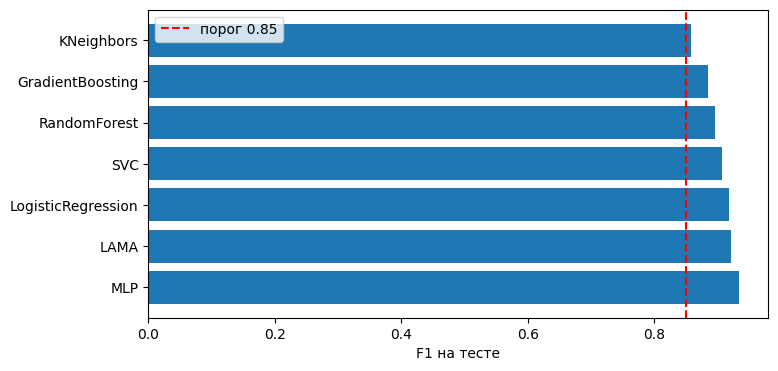

In [9]:
plt.figure(figsize=(8, 4))
plt.barh(results["model"], results["f1"])
plt.axvline(0.85, color="red", linestyle="--", label="порог 0.85")
plt.xlabel("F1 на тесте")
plt.legend()
plt.show()

**Вывод:** все модели набрали F1 выше 0.85. Лучший результат у модели с самым высоким F1
в таблице выше. Тест маленький (51 снимок), поэтому разница между моделями в 1-2 снимка
может быть случайной - для надёжности смотрим ещё колонку `f1_cv5` (кросс-валидация).